In [6]:
import os

print(os.getcwd())
print(os.listdir())

C:\Users\SUJIT\Downloads
['(diwali sales)', '(PDF) Data Mining in Healthcare for Heart Diseases.html', '(PDF) Data Mining in Healthcare for Heart Diseases_files', '+2 Character (1).pdf', '+2 Character.jpeg', '+2 Character.pdf', '+2 Transcript (1).pdf', '+2 Transcript.jpeg', '+2 Transcript.pdf', '+2-character-n.jpg', '.git', '.gitattributes', '.ipynb_checkpoints', '06. Practice Qs.mp4', '08. Functions as Props.mp4', '1-intro (1).ppt', '1-intro.ppt', '1-s2.0-S1877050915036066-main.pdf', '1. AGES.pdf', '10.Information Regarding Students.docx', '10th Certificate (1).pdf', '10th Certificate (2).jpeg', '10th certificate.jpeg', '10th Certificate.jpg', '10th Certificate.pdf', '12th Certificate.jpeg', '12th Certificate.pdf', '12th Certificates.pdf', '12th Marksheet.pdf', '12th Marksheet.pdf.pdf', '14th CONVOCATION Sujit Kumar YADAV (1).docx', '1715605095863.jpg', '1715605416280.jpg', '1776146250_Translation_English_translation.pdf', '1st sem marksheets.pdf', '2-transcript-n.jpg', '2. Percentage

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import accuracy_score, f1_score

print("Libraries imported successfully")

Libraries imported successfully


In [13]:
from sklearn.datasets import load_iris
import pandas as pd

Iris = load_iris()

X = pd.DataFrame(
    Iris.data,
    columns=Iris.feature_names
)

y = pd.Series(Iris.target, name="species")

print(X.head())
print(y.head())

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2
0    0
1    0
2    0
3    0
4    0
Name: species, dtype: int32


In [14]:
print("Mean:")
print(X.mean())

print("\nMedian:")
print(X.median())

print("\nStandard Deviation:")
print(X.std())

print("\nSkewness:")
print(X.skew())

print("\nKurtosis:")
print(X.kurtosis())

Mean:
sepal length (cm)    5.843333
sepal width (cm)     3.057333
petal length (cm)    3.758000
petal width (cm)     1.199333
dtype: float64

Median:
sepal length (cm)    5.80
sepal width (cm)     3.00
petal length (cm)    4.35
petal width (cm)     1.30
dtype: float64

Standard Deviation:
sepal length (cm)    0.828066
sepal width (cm)     0.435866
petal length (cm)    1.765298
petal width (cm)     0.762238
dtype: float64

Skewness:
sepal length (cm)    0.314911
sepal width (cm)     0.318966
petal length (cm)   -0.274884
petal width (cm)    -0.102967
dtype: float64

Kurtosis:
sepal length (cm)   -0.552064
sepal width (cm)     0.228249
petal length (cm)   -1.402103
petal width (cm)    -1.340604
dtype: float64


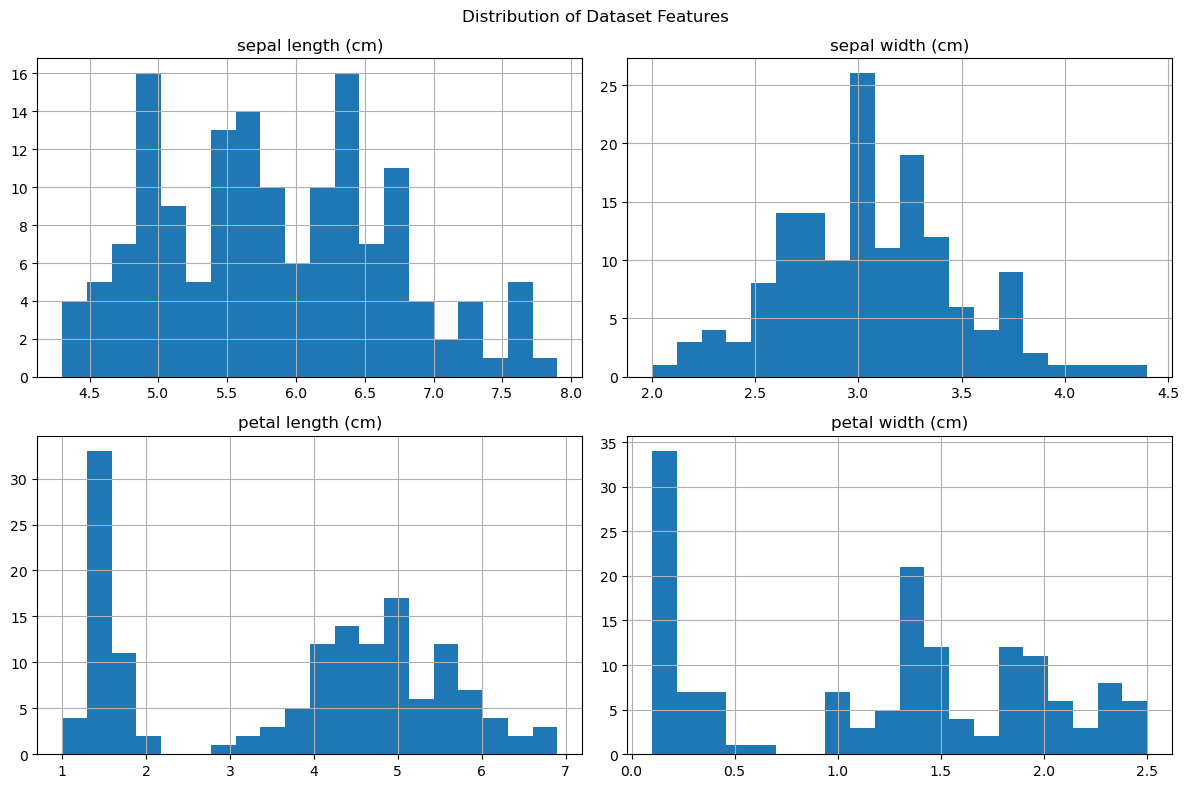

In [15]:
X.hist(figsize=(12, 8), bins=20)

plt.suptitle("Distribution of Dataset Features")
plt.tight_layout()
plt.show()

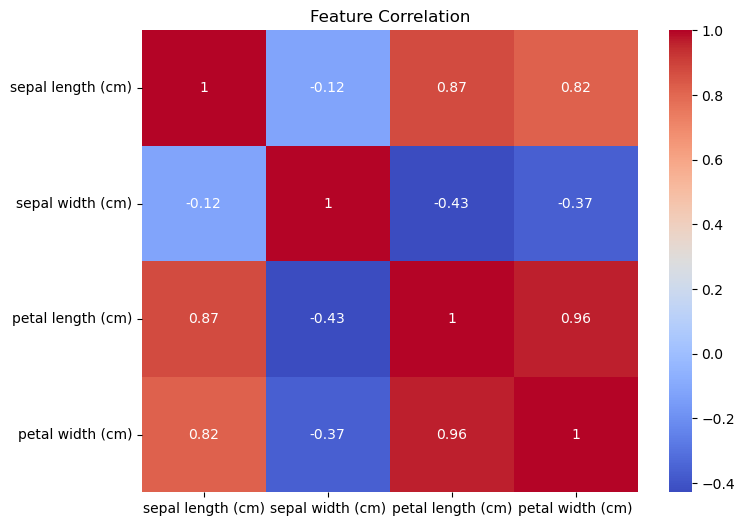

In [16]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    X.corr(),
    annot=True,
    cmap="coolwarm"
)

plt.title("Feature Correlation")
plt.show()

In [17]:
meta_features = {
    "Number of Rows": X.shape[0],
    "Number of Features": X.shape[1],
    "Mean Skewness": X.skew().abs().mean(),
    "Average Variance": X.var().mean(),
    "Missing Values": X.isnull().sum().sum(),
    "Number of Classes": y.nunique()
}

print(pd.Series(meta_features))

Number of Rows        150.000000
Number of Features      4.000000
Mean Skewness           0.252932
Average Variance        1.143239
Missing Values          0.000000
Number of Classes       3.000000
dtype: float64


In [19]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [20]:
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (120, 4)
X_test shape: (30, 4)
y_train shape: (120,)
y_test shape: (30,)


In [21]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "SVM": SVC(),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42)
}

In [22]:
results = []

for name, model in models.items():

    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred, average="weighted")

    results.append({
        "Algorithm": name,
        "Accuracy": accuracy * 100,
        "F1 Score": f1
    })

results_df = pd.DataFrame(results)

print(results_df)

             Algorithm   Accuracy  F1 Score
0  Logistic Regression  93.333333  0.933333
1                  KNN  93.333333  0.932660
2                  SVM  96.666667  0.966583
3        Decision Tree  93.333333  0.933333
4        Random Forest  90.000000  0.899749


In [23]:
best_model = results_df.loc[
    results_df["F1 Score"].idxmax()
]

print("BEST RECOMMENDED MODEL")
print("----------------------")

print("Algorithm:", best_model["Algorithm"])
print("Accuracy:", best_model["Accuracy"])
print("F1 Score:", best_model["F1 Score"])

BEST RECOMMENDED MODEL
----------------------
Algorithm: SVM
Accuracy: 96.66666666666667
F1 Score: 0.9665831244778613


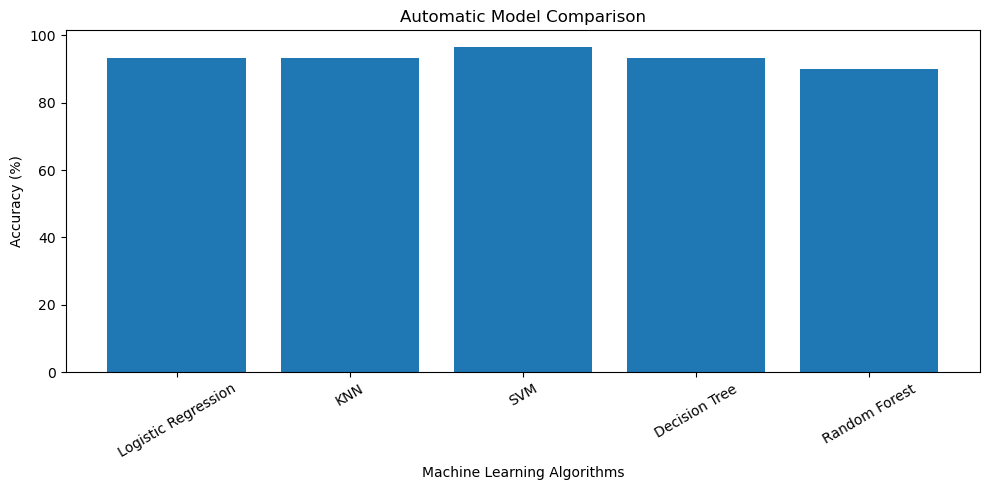

In [24]:
plt.figure(figsize=(10, 5))

plt.bar(
    results_df["Algorithm"],
    results_df["Accuracy"]
)

plt.xlabel("Machine Learning Algorithms")
plt.ylabel("Accuracy (%)")

plt.title("Automatic Model Comparison")

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()